# DASC8412 Assignment 2. Quesiton 7 

## Name: Vastaav Tahir Yuri Singh
## Student Number: ST10063699

In [166]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [167]:
df = pd.read_csv("School_Data_CSV.csv", encoding="latin1")

C:\Users\singh\AppData\Local\Temp\ipykernel_42528\2870176702.py:1: DtypeWarning: Columns (0: emisno, 1: new_long) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("School_Data_CSV.csv", encoding="latin1")


In [191]:
df.head(50)

,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
0,200100005,ABERDEEN SECONDARY SCHOOL (20),ABERDEEN SECONDARY SCHOOL,4201001,3,21001001,"10 PARLIAMENT STREET, ABERDEEN, 6270",24.061830,-32.473850
1,200100012,ADELAIDE GYMNASIUM,ADELAIDE GYMNASIUM,4171044,4,21208001,"WELSH STREET, ADELAIDE, 5760",26.294760,-32.710360
2,200100018,AEROVILLE(SOMERSET EAST) (20),AEROVILLE SECONDARY SCHOOL,4201002,3,21002002,"PERSEVERANCE DR, SOMERSET EAST, 5850",25.600730,-32.745920
3,200100019,Al Azhar Institute,AL-AZHAR PRIMARY SCHOOL,4222001,NOT APPLICABLE,29500009,"42 RUDOLPH STREET, MALABAR, PORT ELIZABETH, 6000",25.535630,-33.919240
4,200100021,ALEXANDER ROAD HIGH SCHOOL,ALEXANDER ROAD HIGH SCHOOL,4221002,5,29300007,"ALEXANDER ROAD, NEWTON PARK, PORT ELIZABETH, 6055",25.571810,-33.941470
5,200100024,ALEXANDRIA HOERSKOOL (21),ALEXANDRIA HIGH SCHOOL,4211001,3,21005002,"KROG EN VOORTREKKER STREET , CBD, ALEXANDRIA,...",26.408670,-33.654110
6,200100030,AMAJINGQI SECONDARY SCHOOL (17),SIPHO CAMAGU HIGH SCHOOL,4171045,3,21208001,"BONANI STREET, ADELAIDE, 5760",26.309720,-32.690110
7,200100033,HOERSKOOL ANDREW RABIE,ANDREW RABIE HIGH SCHOOL,4221026,4,29300007,"ARAGONWEG, ADCOCKVALE, PORT ELIZABETH, 6001",25.581750,-33.943020
8,200100037,ARCADIA SECONDARY SCHOOL (22),ARCADIA SENIOR SECONDARY SCHOOL,4221003,3,29300034,"RENSBURG STREET, ARCADIA, PORT ELIZABETH, 6059",25.520620,-33.878070
9,200100041,ASHERVILLE SECONDARY SCHOOL (20),ASHERVILLE PUBLIC SCHOOL,4201003,3,21001003,"AFFODIL STREET, ASHERVILLE, GRAAFF-REINET, 6280",24.558850,-32.281730


In [169]:
print(df.columns)

Index(['emisno', 'centername', 'institution_name', 'centreno', 'quintile',
       'ward_id', 'street_address', 'new_long', 'new_lat'],
      dtype='str')


In [170]:
print(df.isna().sum())

emisno                   0
centername            5931
institution_name     65927
centreno                30
quintile              2813
ward_id                782
street_address        6703
new_long             32112
new_lat             115746
dtype: int64


In [171]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 766


In [172]:
print(df.dtypes)

emisno               object
centername              str
institution_name        str
centreno                str
quintile                str
ward_id                 str
street_address          str
new_long             object
new_lat             float64
dtype: object


In [173]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 199853 entries, 0 to 199852
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   emisno            199853 non-null  object 
 1   centername        193922 non-null  str    
 2   institution_name  133926 non-null  str    
 3   centreno          199823 non-null  str    
 4   quintile          197040 non-null  str    
 5   ward_id           199071 non-null  str    
 6   street_address    193150 non-null  str    
 7   new_long          167741 non-null  object 
 8   new_lat           84107 non-null   float64
dtypes: float64(1), object(2), str(6)
memory usage: 29.0+ MB
None


In [174]:
print("Dataset shape:", df.shape)

Dataset shape: (199853, 9)


In [ ]:
# ________________Code Attribution___________________
# The following method was taken from ChatGPT:
# Author: ChatGPT
# https://chatgpt.com/ 

print(df["quintile"].value_counts(dropna=False))    
print(df["ward_id"].value_counts(dropna=False))   

#_________________end____________________________

quintile
1                                                    49010
2                                                    40114
3                                                    32288
TO BE UPDATED                                        22300
NOT APPLICABLE                                       16049
5                                                    12916
4                                                    11429
Q1                                                    3760
Q2                                                    3211
Q3                                                    2961
NaN                                                   2813
.                                                      936
Q4                                                     880
Q5                                                     835
NQ2                                                    281
To be updated                                           30
99                                             

In [ ]:
df = df.drop_duplicates().copy()           

In [ ]:
# ________________Code Attribution___________________
# The following method was taken from ChatGPT:
# Author: ChatGPT
# https://chatgpt.com/ 

# Convert relevant columns to numeric
df["quintile"] = pd.to_numeric(df["quintile"], errors="coerce")         
df["ward_id"] = pd.to_numeric(df["ward_id"], errors="coerce")         
df["new_long"] = pd.to_numeric(df["new_long"], errors="coerce")        
df["new_lat"] = pd.to_numeric(df["new_lat"], errors="coerce")     

#_________________end_____________________

In [ ]:
# Save the cleaned dataset
df.to_csv("School_Data_CSV_Cleaned.csv", index=False)                  

# Graphs 
## Below code is sourced from ChatGPT

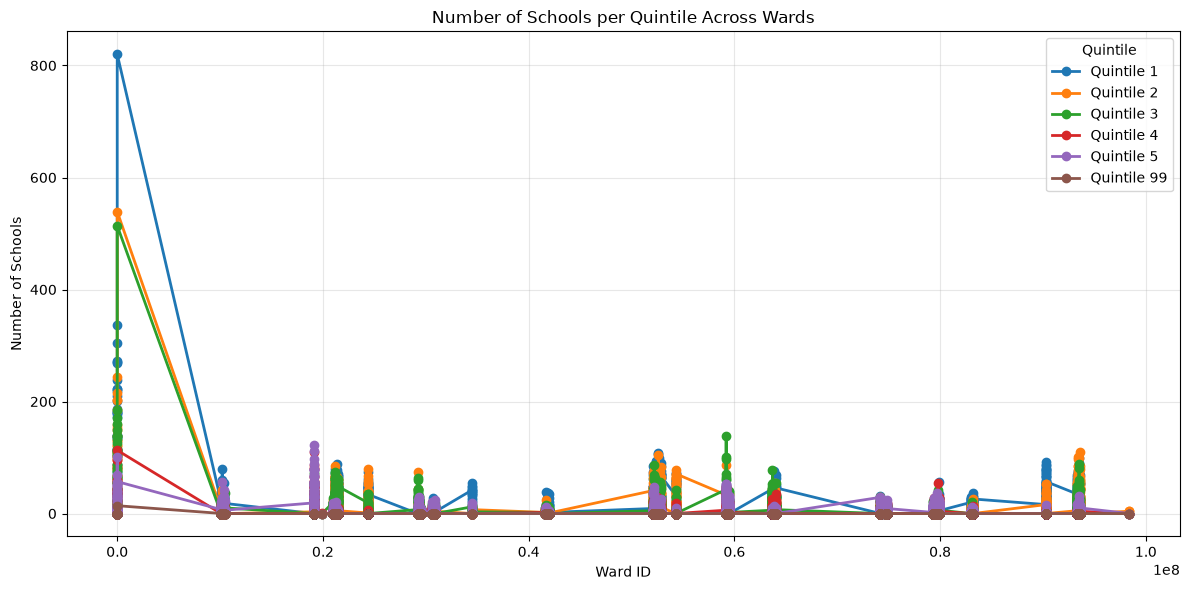

In [ ]:
# ________________Code Attribution___________________
# The following method was taken from ChatGPT:
# Author: ChatGPT
# https://chatgpt.com/ 

# --------------------------------------------------
# A) LINE CHART: Number of Schools per Quintile Across Wards
# --------------------------------------------------

# Exclude records without a valid ward or quintile
line_data = df.dropna(subset=["ward_id", "quintile"]).copy()

# Count schools for each ward and quintile
ward_counts = (
    line_data.groupby(["ward_id", "quintile"])
    .size()
    .reset_index(name="number_of_schools")
)

# Arrange counts into a table for plotting
line_pivot = ward_counts.pivot(
    index="ward_id",
    columns="quintile",
    values="number_of_schools"
).fillna(0)

# Create the line plot
plt.figure(figsize=(12, 6))

for quintile in line_pivot.columns:
    plt.plot(
        line_pivot.index,
        line_pivot[quintile],
        marker="o",
        linewidth=2,
        label=f"Quintile {int(quintile)}"
    )

plt.title("Number of Schools per Quintile Across Wards")
plt.xlabel("Ward ID")
plt.ylabel("Number of Schools")
plt.legend(title="Quintile")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
#____________________end______________________


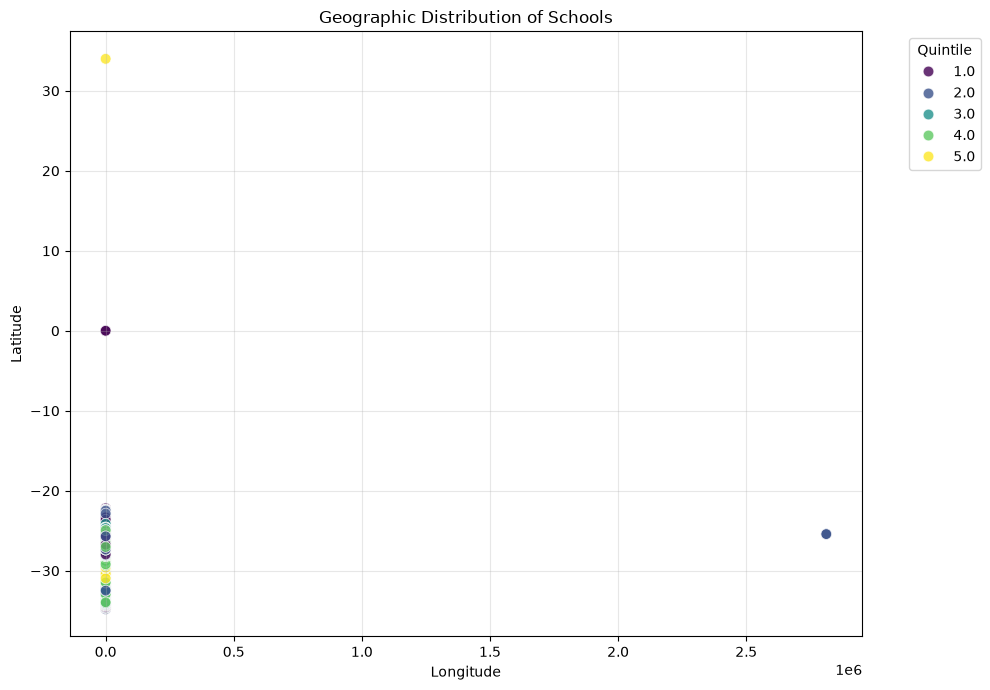

In [ ]:
# ________________Code Attribution___________________
# The following method was taken from ChatGPT:
# Author: ChatGPT
# https://chatgpt.com/ 


# --------------------------------------------------
# B) SCATTER PLOT: Geographic locations of schools
# --------------------------------------------------

# Keep schools with valid geographic coordinates
geo_data = df.dropna(subset=["new_long", "new_lat"])

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=geo_data,
    x="new_long",
    y="new_lat",
    hue="quintile",
    palette="viridis",
    s=60,
    alpha=0.8
)

plt.title("Geographic Distribution of Schools")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Quintile", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
#____________________end_____________________


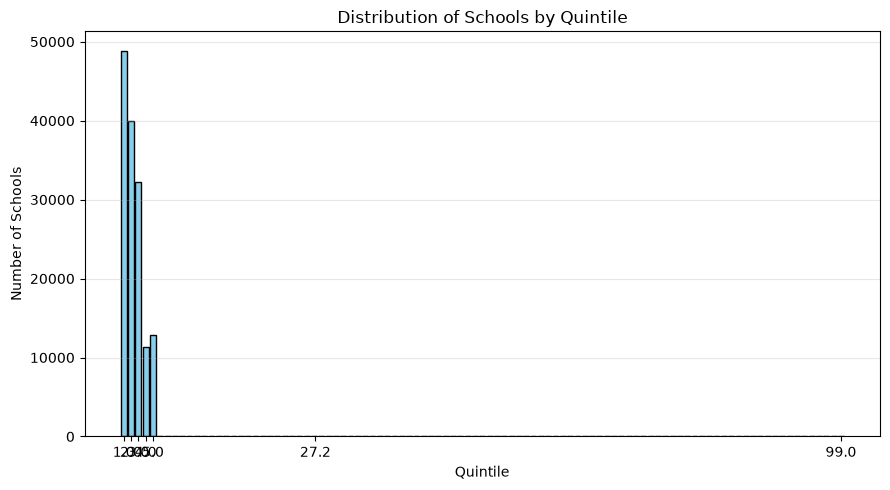

In [ ]:
# ________________Code Attribution___________________
# The following method was taken from ChatGPT:
# Author: ChatGPT
# https://chatgpt.com/ 

# --------------------------------------------------
# C) BAR CHART: Distribution of schools by quintile
# --------------------------------------------------

# Exclude missing quintile values
hist_data = df.dropna(subset=["quintile"]).copy()

plt.figure(figsize=(9, 5))

bins = range(
    int(hist_data["quintile"].min()),
    int(hist_data["quintile"].max()) + 2
)

plt.hist(
    hist_data["quintile"],
    bins=bins,
    align="left",
    edgecolor="black",
    color="skyblue",
    rwidth=0.8
)

plt.title("Distribution of Schools by Quintile")
plt.xlabel("Quintile")
plt.ylabel("Number of Schools")
plt.xticks(sorted(hist_data["quintile"].unique()))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
#____________________end_____________________

# Code from Claude
# Code sourced from Claude AI

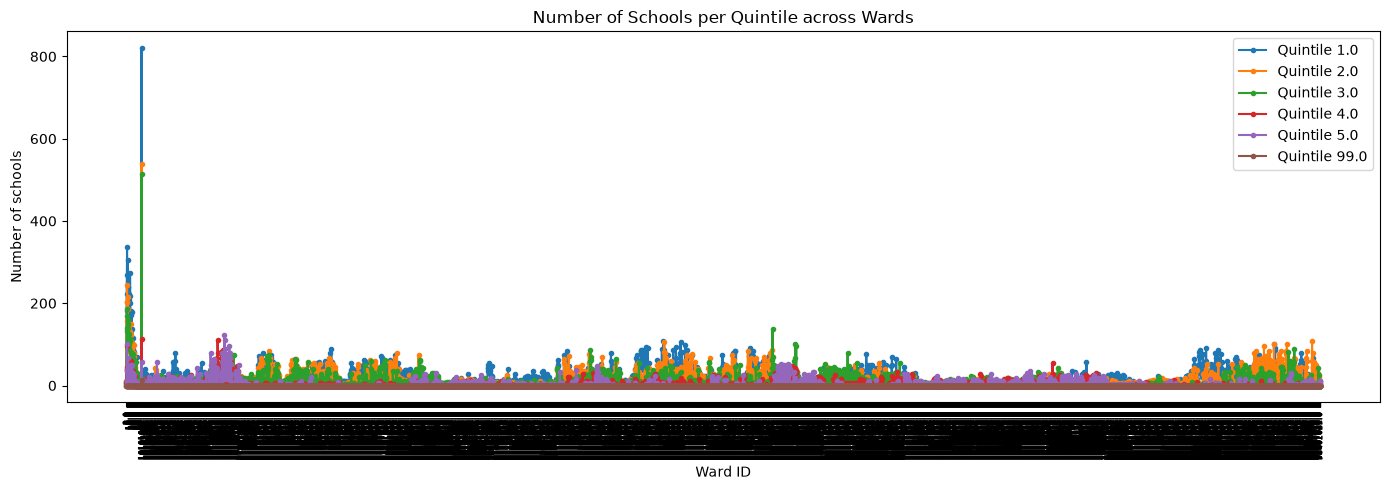

In [ ]:
# ________________Code Attribution___________________
# The following method was taken from Claude:
# Author: Claude
# https://chatgpt.com/ 


# (a) Line plot: number of schools per quintile across wards
counts = (df.groupby(["ward_id", "quintile"]).size()
            .unstack(fill_value=0)
            .sort_index())

plt.figure(figsize=(14, 5))
for q in counts.columns:
    plt.plot(counts.index.astype(str), counts[q], marker="o", markersize=3,
             label=f"Quintile {q}")
plt.title("Number of Schools per Quintile across Wards")
plt.xlabel("Ward ID")
plt.ylabel("Number of schools")
plt.xticks(rotation=90, fontsize=6)
plt.legend()
plt.tight_layout()
plt.show()
#____________________end_____________________

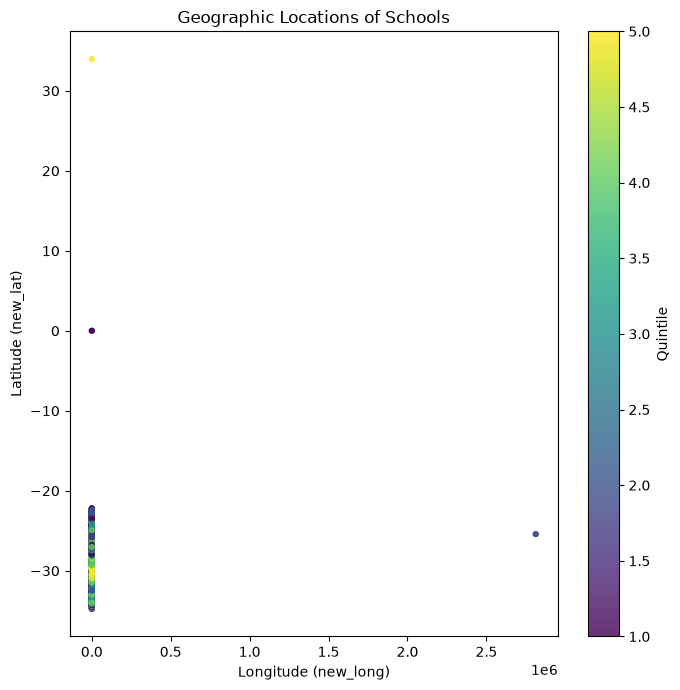

In [ ]:
# ________________Code Attribution___________________
# The following method was taken from Claude:
# Author: Claude
# https://claude.ai/

# (b) Scatter plot: geographic locations of schools
geo = df.dropna(subset=["new_lat", "new_long"])

plt.figure(figsize=(7, 7))
sc = plt.scatter(geo["new_long"], geo["new_lat"], c=geo["quintile"],
                 cmap="viridis", s=12, alpha=0.8)
plt.colorbar(sc, label="Quintile")
plt.title("Geographic Locations of Schools")
plt.xlabel("Longitude (new_long)")
plt.ylabel("Latitude (new_lat)")
plt.tight_layout()
plt.show()
#____________________end_____________________

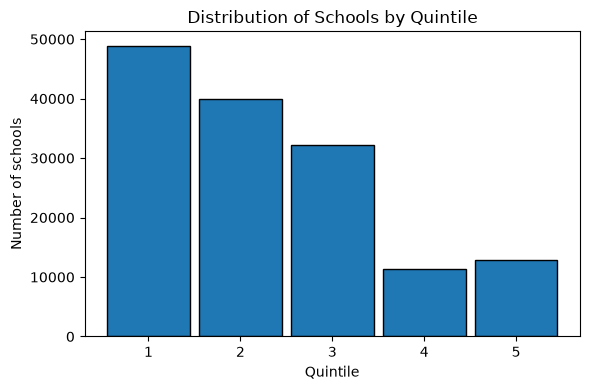

In [ ]:
# ________________Code Attribution___________________
# The following method was taken from Claude:
# Author: Claude
# https://claude.ai/

# (c) Histogram: distribution of schools by quintile
plt.figure(figsize=(6, 4))
plt.hist(df["quintile"], bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
         edgecolor="black", rwidth=0.9)
plt.title("Distribution of Schools by Quintile")
plt.xlabel("Quintile")
plt.ylabel("Number of schools")
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()
#____________________end_____________________

# References 
ChatGPT. 2026. Chat-GPT (Version 6). [Large language model]. Available at: https://chat.openai.com/ [Accessed: 14 October 2026].

Claude AI. 2026. Claude (Version 5.5). [Large language model]. Available at: https://claude.ai/ [Accessed: 14 October 2026].